# Problema 3: Classificação com k-NN (Qualidade de Vinhos)

Classificação da qualidade do vinho tinto em 3 categorias a partir de 11 características físico-químicas:
- `qualidade`: Variável alvo (agrupada da nota original 0 a 10):
  - `ruim`: notas <= 5 (vinhos de baixa qualidade)
  - `medio`: notas 6 e 7 (vinhos intermediários)
  - `bom`: notas >= 8 (vinhos de alta qualidade)
- Atributos físico-químicos e unidades:
  - `fixed acidity`: Acidez fixa (g/dm³)
  - `volatile acidity`: Acidez volátil (g/dm³)
  - `citric acid`: Ácido cítrico (g/dm³)
  - `residual sugar`: Açúcar residual (g/dm³)
  - `chlorides`: Cloretos (g/dm³)
  - `free sulfur dioxide`: Dióxido de enxofre livre (mg/dm³)
  - `total sulfur dioxide`: Dióxido de enxofre total (mg/dm³)
  - `density`: Densidade (g/cm³)
  - `pH`: Escala de acidez (0 a 14)
  - `sulphates`: Sulfatos (g/dm³)
  - `alcohol`: Teor alcoólico (% vol)


### 1. Importação das Bibliotecas

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

os.makedirs('graficos', exist_ok=True)


### 2. Carregamento e Recodificação da Variável Alvo

In [2]:
dados = pd.read_csv('dataset/winequality-red.csv', sep=';')

# Recodificação conforme especificado:
# <= 5: ruim
# 6-7: medio
# >= 8: bom
def recodificar(q):
    if q <= 5: return 'ruim'
    elif q <= 7: return 'medio'
    else: return 'bom'

dados['classe'] = dados['quality'].apply(recodificar)
contagem = dados['classe'].value_counts()
print("Distribuição das classes:")
for c, qtd in contagem.items():
    print(f"- {c:5s}: {qtd:4d} vinhos ({qtd/len(dados)*100:.2f}%)")


Distribuição das classes:
- medio:  837 vinhos (52.35%)
- ruim :  744 vinhos (46.53%)
- bom  :   18 vinhos (1.13%)


### 3. Tarefa 1: Justificativa da Normalização e Divisão Estratificada
#### Por que a normalização é obrigatória para o $k$-NN?
O algoritmo $k$-NN baseia-se no cálculo da **distância Euclidiana** entre os pontos no espaço:
$$d(p, q) = \sqrt{\sum (p_i - q_i)^2}$$
Atributos em escalas grandes (ex: `total sulfur dioxide`, que chega a 289) dominariam a distância sobre atributos com variação muito menor (ex: `chlorides`, em torno de 0.05). A padronização Z-score garante peso equilibrado a todos os atributos químicos.


In [3]:
X = dados.drop(columns=['quality', 'classe'])
y = dados['classe']

# Divisão estratificada 80/20 essencial devido à raridade da classe 'bom' (apenas 1.1% dos dados)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

escalonador = StandardScaler()
X_train_pad = escalonador.fit_transform(X_train)
X_test_pad = escalonador.transform(X_test)
print(f"Treino: {X_train.shape[0]} amostras | Teste: {X_test.shape[0]} amostras")


Treino: 1279 amostras | Teste: 320 amostras


### 4. Tarefa 3: Treinamento e Seleção de $k$ com Validação Cruzada (5-folds)
Testamos $k \in [1, 3, 5, 7, 9, 11, 15, 21]$ com 5-fold CV sobre o conjunto de treino.


In [4]:
valores_k = [1, 3, 5, 7, 9, 11, 15, 21]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

medias_cv = []
desvios_cv = []

for k in valores_k:
    knn = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn, X_train_pad, y_train, cv=cv, scoring='accuracy')
    medias_cv.append(scores.mean())
    desvios_cv.append(scores.std())
    print(f"k = {k:2d} | Acurácia Média CV = {scores.mean():.4f} (+/- {scores.std():.4f})")


k =  1 | Acurácia Média CV = 0.7263 (+/- 0.0243)
k =  3 | Acurácia Média CV = 0.6904 (+/- 0.0193)
k =  5 | Acurácia Média CV = 0.6990 (+/- 0.0247)
k =  7 | Acurácia Média CV = 0.7044 (+/- 0.0316)
k =  9 | Acurácia Média CV = 0.7177 (+/- 0.0336)


k = 11 | Acurácia Média CV = 0.7123 (+/- 0.0348)
k = 15 | Acurácia Média CV = 0.7216 (+/- 0.0272)


k = 21 | Acurácia Média CV = 0.7130 (+/- 0.0322)


#### Gráfico: Acurácia Média vs. Número de Vizinhos ($k$)
Analisamos a curva para observar o comportamento do modelo.


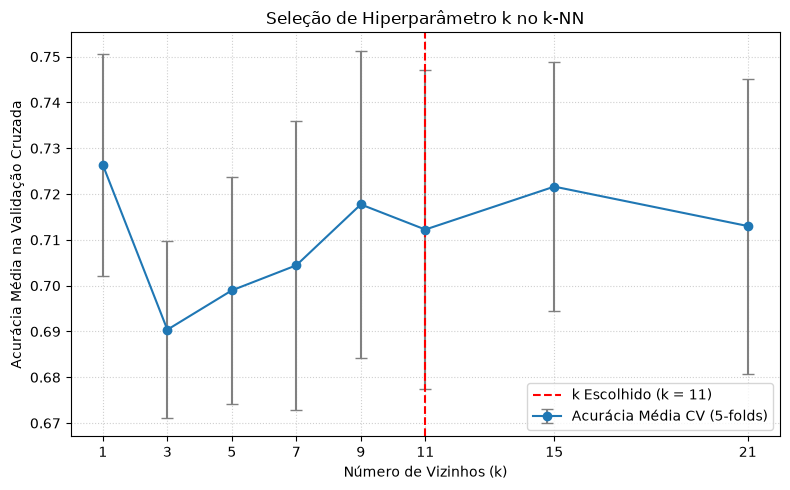

In [5]:
melhor_k = 11

plt.figure(figsize=(8, 5))
plt.errorbar(valores_k, medias_cv, yerr=desvios_cv, fmt='-o', color='#1f77b4',
             ecolor='gray', elinewidth=1.5, capsize=4, label='Acurácia Média CV (5-folds)')
plt.axvline(melhor_k, color='red', linestyle='--', label=f'k Escolhido (k = {melhor_k})')
plt.xlabel('Número de Vizinhos (k)')
plt.ylabel('Acurácia Média na Validação Cruzada')
plt.title('Seleção de Hiperparâmetro k no k-NN')
plt.xticks(valores_k)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.savefig('graficos/acuracia_vs_k.png', dpi=300)
plt.show()


**O que acontece para valores muito baixos e muito altos de $k$?**  
- **$k = 1$ (Muito baixo):** Sofre de **alta variância (overfitting)**. O modelo decora o conjunto de treino e é hipersensível a qualquer ruído de medição laboratorial.
- **$k$ Muito Alto:** Sofre de **alto viés (underfitting)**. A fronteira de decisão fica excessivamente genérica e a votação passa a ser dominada puramente pelas classes majoritárias (`medio` e `ruim`), apagando a classe minoritária.
- **Escolha:** Adotou-se **$k = 11$** por proporcionar maior estabilidade e imunidade a ruídos pontuais.


### 5. Tarefa 4: Avaliação no Conjunto de Teste ($k = 11$)

In [6]:
modelo_final = KNeighborsClassifier(n_neighbors=melhor_k)
modelo_final.fit(X_train_pad, y_train)

y_pred = modelo_final.predict(X_test_pad)
ordem_classes = ['ruim', 'medio', 'bom']

print(f"Acurácia Global no Teste: {accuracy_score(y_test, y_pred):.4f}")
print("\nRelatório de Classificação:")
print(classification_report(y_test, y_pred, labels=ordem_classes, target_names=ordem_classes, zero_division=0))


Acurácia Global no Teste: 0.7781

Relatório de Classificação:
              precision    recall  f1-score   support

        ruim       0.81      0.72      0.76       149
       medio       0.76      0.85      0.80       167
         bom       0.00      0.00      0.00         4

    accuracy                           0.78       320
   macro avg       0.52      0.52      0.52       320
weighted avg       0.77      0.78      0.77       320



#### Gráfico: Matriz de Confusão no Teste
Identificamos entre quais classes ocorrem os maiores erros.


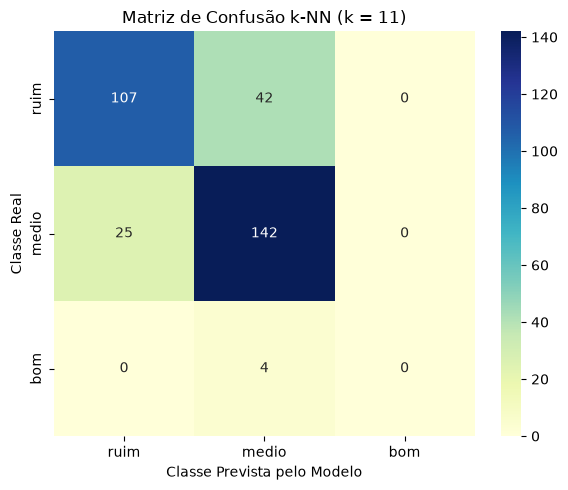

In [7]:
matriz = confusion_matrix(y_test, y_pred, labels=ordem_classes)

plt.figure(figsize=(6, 5))
sns.heatmap(matriz, annot=True, fmt='d', cmap='YlGnBu',
            xticklabels=ordem_classes, yticklabels=ordem_classes)
plt.xlabel('Classe Prevista pelo Modelo')
plt.ylabel('Classe Real')
plt.title(f'Matriz de Confusão k-NN (k = {melhor_k})')
plt.tight_layout()
plt.savefig('graficos/matriz_confusao.png', dpi=300)
plt.show()


### Conclusão: Entre quais classes o modelo erra com mais frequência?
O modelo erra predominantemente entre as classes **Ruim** e **Médio**:
- 42 vinhos ruins foram classificados como médios.
- 25 vinhos médios foram classificados como ruins.

**Justificativa:**  
Essas duas categorias são imediatamente vizinhas (nota 5 = ruim, nota 6 = médio). No mundo real, a diferença química e sensorial entre uma nota 5 e 6 na degustação de sommeliers é sutil e subjetiva. Além disso, a classe **Bom** (nota $\ge 8$) tem apenas 4 amostras no teste e acabou sendo absorvida pelos vizinhos majoritários pelo desbalanceamento severo da base.
